# 09 - La TODO liste, suivie avec TensorBoard

Ce notebook reprend tous les points de `todo.md` dans l'ordre :

1. **Données** : fuites de données, encodage one-hot / cyclique, normalisation
2. **Référence** : baseline naïve, régression linéaire, métrique commune, seeds
3. **Descente de gradient** : learning rates, optimiseurs, architectures, learning rate schedules
4. **Régularisation** : dropout, early stopping, batch size, batch normalization, L1/L2, combinaison
5. **Évaluation** : tableau récapitulatif, test final, résidus
6. **Sauvegarde** : modèles, historiques, configuration

**Suivi avec TensorBoard** : chaque entraînement écrit ses courbes dans `logs/09_todo/<groupe>/<essai>`.
Dans TensorBoard :
- onglet **Scalars** (ou *Time Series*) : courbes `epoch_mae` train/validation, filtrables par groupe avec la regex (ex. `02_optimiseurs`) ;
- onglet **HParams** : tableau de tous les essais avec leurs hyperparamètres et la MAE de validation finale (`val_mae_velos`) ;
- onglet **Images** : graphique prédictions vs réalité du meilleur modèle (section 5).

**Pas de réentraînement inutile** : chaque modèle est sauvegardé dans `modeles/09_todo/`. Si on relance le notebook,
les modèles déjà entraînés sont rechargés. Mettre `FORCE = True` pour tout réentraîner.

> Métrique commune à tous les essais : **MAE en nombre de vélos** sur le jeu de validation.
> Le jeu de test n'est utilisé **qu'une seule fois**, à la toute fin.

In [1]:
import io
import json
import shutil
import time
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorboard.plugins.hparams import api as hp

from velo_utils import load_raw, prepare, plot_history, PALETTE, TARGET, DROPPED

SEED = 42
EPOCHS = 200
TARGET_SCALE = 1000.0               # cible en milliers de locations
LOG_DIR = Path("logs/09_todo")
MODEL_DIR = Path("modeles/09_todo")
FORCE = False                       # True : réentraîne tout, même si un modèle sauvegardé existe

keras.utils.set_random_seed(SEED)   # reproductibilité
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


### Lancer TensorBoard

La cellule suivante ouvre TensorBoard directement dans le notebook. Les courbes apparaissent au fur et à mesure
des entraînements (cliquer sur le bouton de rafraîchissement en haut à droite).

Alternative dans un terminal : `tensorboard --logdir notebooks/logs/09_todo` puis ouvrir http://localhost:6006

In [2]:
%load_ext tensorboard
%tensorboard --logdir logs/09_todo

## 1. Données

### 1.1 Fuites de données

`casual + registered = cnt` : garder ces colonnes reviendrait à donner la réponse au modèle.
`instant` et `dteday` sont des identifiants (l'information utile est déjà dans `yr`, `mnth`, `weekday`).
`prepare()` de `velo_utils` les retire ; on le vérifie.

In [3]:
raw = load_raw()
print("casual + registered == cnt :", (raw["casual"] + raw["registered"] == raw["cnt"]).all())

df_onehot = prepare(target_scale=TARGET_SCALE)
assert not set(DROPPED) & set(df_onehot.columns), "fuite de données !"
print(df_onehot.shape, "->", list(df_onehot.columns))

casual + registered == cnt : True
(731, 34) -> ['yr', 'holiday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed', 'cnt', 'season_1', 'season_2', 'season_3', 'season_4', 'mnth_1', 'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12', 'weekday_0', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6', 'weathersit_1', 'weathersit_2', 'weathersit_3']


### 1.2 Encodage cyclique

Le one-hot ne sait pas que décembre est proche de janvier. L'encodage cyclique place chaque mois (et chaque jour de la semaine)
sur un cercle : $\sin(2\pi \cdot x / T)$ et $\cos(2\pi \cdot x / T)$, avec $T = 12$ pour les mois et $T = 7$ pour les jours.

(731, 19) -> ['yr', 'holiday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed', 'cnt', 'mnth_sin', 'mnth_cos', 'weekday_sin', 'weekday_cos', 'season_1', 'season_2', 'season_3', 'season_4', 'weathersit_1', 'weathersit_2', 'weathersit_3']


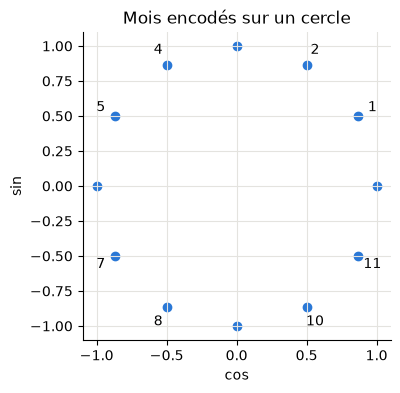

In [4]:
CYCLIC = {"mnth": 12, "weekday": 7}

def prepare_cyclic(df=None, target_scale=TARGET_SCALE):
    # Comme prepare(), mais mnth et weekday en sin/cos au lieu du one-hot.
    df = load_raw() if df is None else df
    df = df.drop(columns=DROPPED)
    for col, period in CYCLIC.items():
        df[col + "_sin"] = np.sin(2 * np.pi * df[col] / period)
        df[col + "_cos"] = np.cos(2 * np.pi * df[col] / period)
    df = df.drop(columns=list(CYCLIC))
    df = pd.get_dummies(df, columns=["season", "weathersit"], dtype="float32")
    df = df.astype("float32")
    df[TARGET] = df[TARGET] / target_scale
    return df

df_cyclic = prepare_cyclic()
print(df_cyclic.shape, "->", list(df_cyclic.columns))

fig, ax = plt.subplots(figsize=(4, 4))
months = np.arange(1, 13)
ax.scatter(np.cos(2 * np.pi * months / 12), np.sin(2 * np.pi * months / 12), color=PALETTE[0])
for m in months:
    ax.annotate(m, (np.cos(2 * np.pi * m / 12) * 1.12, np.sin(2 * np.pi * m / 12) * 1.12), ha="center", va="center")
ax.set(title="Mois encodés sur un cercle", xlabel="cos", ylabel="sin", aspect="equal")
plt.show()

### 1.3 Découpage train / validation / test

- **test** (20 %) : mis de côté, utilisé une seule fois à la fin ;
- **validation** (20 % du reste) : sert à comparer tous les essais. Le même jeu de validation est utilisé partout,
  contrairement à `validation_split` qui dépend de l'ordre des lignes.

Les lignes choisies sont les mêmes pour les deux encodages (même `random_state` sur le même index).

In [5]:
def three_way_split(df):
    full_train = df.sample(frac=0.8, random_state=0)   # même test que les notebooks précédents
    test = df.drop(full_train.index)
    train = full_train.sample(frac=0.8, random_state=1)
    val = full_train.drop(train.index)
    to_xy = lambda d: (d.drop(columns=TARGET).to_numpy(), d[TARGET].to_numpy())
    return {"train": to_xy(train), "val": to_xy(val), "test": to_xy(test), "test_index": test.index}

DATASETS = {"onehot": three_way_split(df_onehot), "cyclique": three_way_split(df_cyclic)}
for name, d in DATASETS.items():
    print(f"{name:9s} train {d['train'][0].shape} | val {d['val'][0].shape} | test {d['test'][0].shape}")

onehot    train (468, 33) | val (117, 33) | test (146, 33)
cyclique  train (468, 18) | val (117, 18) | test (146, 18)


### 1.4 Normalisation

La normalisation est faite **dans le modèle** par une couche `Normalization`, adaptée **sur le train uniquement**
(`norm.adapt(X_train)`). Avantages : pas de fuite depuis la validation ou le test, et les moyennes/variances
sont sauvegardées avec le modèle dans le fichier `.keras`.

> Pour aller plus loin : `hour.csv` (même dataset, à l'heure, ~17 000 lignes au lieu de 731) donnerait beaucoup plus
> de données. Il faudrait l'ajouter dans `data/` et ajouter `hr` aux variables cycliques ($T = 24$).

## 2. Outils de suivi

- `make_model(...)` : construit un MLP paramétrable (couches, activation, optimiseur, dropout, batch norm, L1/L2) ;
- `run(...)` : entraîne le modèle (ou le recharge s'il est déjà sauvegardé), écrit les logs TensorBoard,
  les hyperparamètres (onglet HParams), sauvegarde le modèle + l'historique, et ajoute une ligne au tableau `results`.

In [6]:
def make_model(hidden=(64, 64), activation="relu", optimizer=None, dropout=0.0,
               batchnorm=False, l1=0.0, l2=0.0, data="onehot"):
    # MLP : Normalization (stats du train) -> couches cachées -> 1 sortie linéaire.
    X = DATASETS[data]["train"][0]
    norm = layers.Normalization()
    norm.adapt(X)
    reg = keras.regularizers.L1L2(l1=l1, l2=l2) if (l1 or l2) else None
    model = keras.Sequential([keras.Input(shape=(X.shape[1],)), norm])
    for units in hidden:
        model.add(layers.Dense(units, use_bias=not batchnorm, kernel_regularizer=reg))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation(activation))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))
    # loss = MAE (+ pénalité L1/L2 éventuelle) ; la métrique "mae" reste comparable entre tous les essais
    model.compile(optimizer=optimizer or keras.optimizers.Adam(learning_rate=1e-3), loss="mae", metrics=["mae"])
    return model


results = {}  # une ligne par essai, indexée par "groupe/nom"

def run(group, name, build, hparams, data="onehot", epochs=EPOCHS, batch_size=32, callbacks=()):
    # Entraîne (ou recharge) un modèle et journalise tout dans TensorBoard.
    run_id = f"{group}/{name}"
    logdir = LOG_DIR / group / name
    model_path = MODEL_DIR / group / f"{name}.keras"
    hist_path = model_path.with_suffix(".history.json")
    (Xtr, ytr), (Xva, yva) = DATASETS[data]["train"], DATASETS[data]["val"]

    if model_path.exists() and hist_path.exists() and not FORCE:
        model = keras.models.load_model(model_path)
        history = json.loads(hist_path.read_text())
        status, duration = "rechargé", 0.0
    else:
        shutil.rmtree(logdir, ignore_errors=True)
        keras.utils.set_random_seed(SEED)  # mêmes poids initiaux pour tous les essais
        model = build()
        tb = keras.callbacks.TensorBoard(log_dir=str(logdir), histogram_freq=10)
        start = time.time()
        h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=batch_size,
                      callbacks=[tb, *callbacks], verbose=0)
        duration = time.time() - start
        history = {k: [float(v) for v in vals] for k, vals in h.history.items()}
        model_path.parent.mkdir(parents=True, exist_ok=True)
        model.save(model_path)
        hist_path.write_text(json.dumps(history))
        status = "entraîné"

    val_mae = model.evaluate(Xva, yva, verbose=0, return_dict=True)["mae"] * TARGET_SCALE

    if status == "entraîné":
        # Onglet HParams : hyperparamètres + score final de l'essai
        clean = {k: v if isinstance(v, (bool, int, float, str)) else str(v) for k, v in hparams.items()}
        with tf.summary.create_file_writer(str(logdir)).as_default():
            hp.hparams({"groupe": group, "données": data, "batch_size": batch_size, **clean}, trial_id=run_id)
            tf.summary.scalar("val_mae_velos", val_mae, step=0)

    results[run_id] = {"groupe": group, "essai": name, "données": data, "batch_size": batch_size, **hparams,
                       "époques": len(history["loss"]), "MAE val (vélos)": round(val_mae),
                       "durée (s)": round(duration, 1), "chemin": str(model_path)}
    print(f"{run_id:40s} MAE val = {val_mae:6.0f} vélos  ({status}, {len(history['loss'])} époques)")
    return model, SimpleNamespace(history=history)  # même interface qu'un History Keras pour plot_history


def show(group):
    # Tableau des essais d'un groupe, du meilleur au moins bon.
    df = pd.DataFrame([r for r in results.values() if r["groupe"] == group]).drop(columns=["groupe", "chemin"])
    display(df.dropna(axis=1, how="all").sort_values("MAE val (vélos)"))

## 3. Référence

Avant de tester des réseaux, on fixe des points de comparaison :
- **baseline naïve** : prédire toujours la moyenne du train ;
- **régression linéaire** : un seul neurone, sans couche cachée ;
- **MLP de base** : 2 × 64 ReLU, Adam 1e-3, batch 32 ; c'est le modèle que toutes les sections suivantes font varier.

00_reference/naive                       MAE val =   1601 vélos
00_reference/lineaire                    MAE val =    685 vélos  (rechargé, 200 époques)
00_reference/mlp_2x64                    MAE val =    667 vélos  (rechargé, 200 époques)


,essai,données,MAE val (vélos),batch_size,couches,lr,époques,durée (s)
2,mlp_2x64,onehot,667,32.0,"(64, 64)",0.001,200.0,0.0
1,lineaire,onehot,685,32.0,(),0.100,200.0,0.0
0,naive,onehot,1601,NaN,NaN,NaN,NaN,NaN


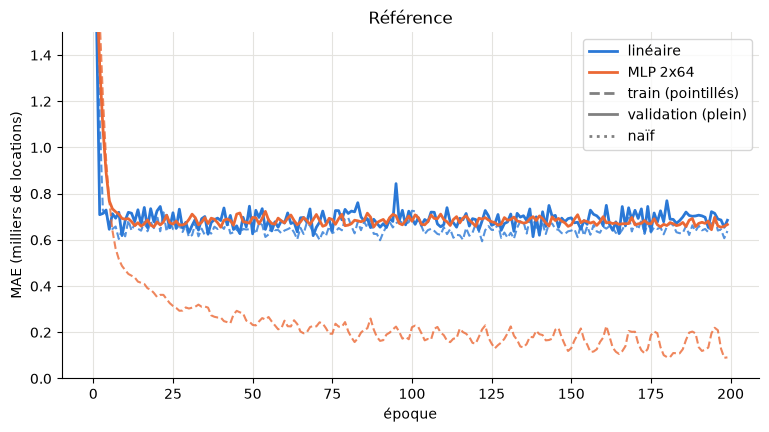

In [7]:
ytr, yva = DATASETS["onehot"]["train"][1], DATASETS["onehot"]["val"][1]
naive_mae = np.mean(np.abs(yva - ytr.mean())) * TARGET_SCALE
results["00_reference/naive"] = {"groupe": "00_reference", "essai": "naive", "données": "onehot",
                                 "MAE val (vélos)": round(naive_mae)}
print(f"00_reference/naive                       MAE val = {naive_mae:6.0f} vélos")

ref = {}
_, ref["linéaire"] = run("00_reference", "lineaire",
                         lambda: make_model(hidden=(), optimizer=keras.optimizers.Adam(0.1)),
                         {"couches": "()", "lr": 0.1})
_, ref["MLP 2x64"] = run("00_reference", "mlp_2x64", lambda: make_model(), {"couches": "(64, 64)", "lr": 1e-3})

show("00_reference")
plot_history(ref, metric="mae", title="Référence", ylim=(0, 1.5))
plt.axhline(naive_mae / TARGET_SCALE, color="gray", ls=":", label="naïf")
plt.legend(); plt.show()

### One-hot ou cyclique ?

00_encodage/onehot                       MAE val =    667 vélos  (rechargé, 200 époques)
00_encodage/cyclique                     MAE val =    565 vélos  (rechargé, 200 époques)


,essai,données,batch_size,encodage,époques,MAE val (vélos),durée (s)
1,cyclique,cyclique,32,cyclique,200,565,0.0
0,onehot,onehot,32,onehot,200,667,0.0


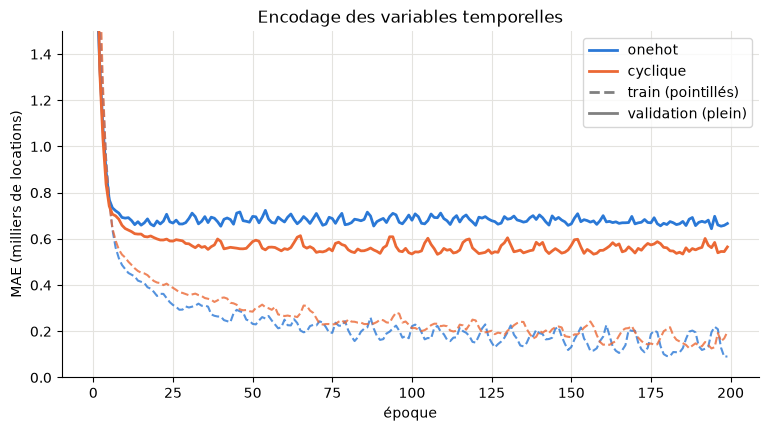

In [8]:
enc = {}
for data in DATASETS:
    _, enc[data] = run("00_encodage", data, lambda: make_model(data=data), {"encodage": data}, data=data)

show("00_encodage")
plot_history(enc, metric="mae", title="Encodage des variables temporelles", ylim=(0, 1.5)); plt.show()

## 4. Descente de gradient

### 4.1 Learning rate (Adam)

Trop grand : la loss oscille ou diverge. Trop petit : l'apprentissage est très lent.

01_learning_rate/adam_lr0.1              MAE val =    645 vélos  (rechargé, 200 époques)
01_learning_rate/adam_lr0.01             MAE val =    657 vélos  (rechargé, 200 époques)
01_learning_rate/adam_lr0.001            MAE val =    667 vélos  (rechargé, 200 époques)
01_learning_rate/adam_lr0.0001           MAE val =    682 vélos  (rechargé, 200 époques)


,essai,données,batch_size,lr,époques,MAE val (vélos),durée (s)
0,adam_lr0.1,onehot,32,0.1000,200,645,0.0
1,adam_lr0.01,onehot,32,0.0100,200,657,0.0
2,adam_lr0.001,onehot,32,0.0010,200,667,0.0
3,adam_lr0.0001,onehot,32,0.0001,200,682,0.0


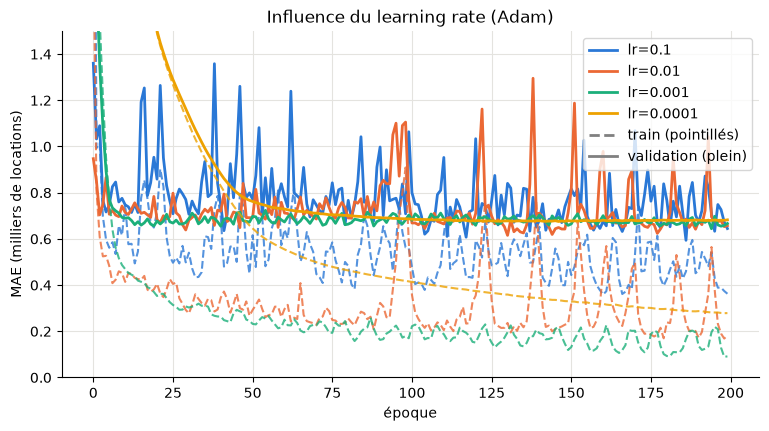

In [9]:
lrs = {}
for lr in [1e-1, 1e-2, 1e-3, 1e-4]:
    _, lrs[f"lr={lr:g}"] = run("01_learning_rate", f"adam_lr{lr:g}",
                               lambda: make_model(optimizer=keras.optimizers.Adam(lr)), {"lr": lr})

show("01_learning_rate")
plot_history(lrs, metric="mae", title="Influence du learning rate (Adam)", ylim=(0, 1.5)); plt.show()

### 4.2 Optimiseurs

Ceux de la slide (`tf.keras.optimizers.*`), plus SGD avec momentum. Chacun avec un learning rate raisonnable pour lui :
Adadelta adapte lui-même son pas et s'utilise avec `learning_rate=1.0` (avec la valeur par défaut de Keras, 0.001, il n'apprend presque rien).

02_optimiseurs/SGD                       MAE val =    731 vélos  (rechargé, 200 époques)
02_optimiseurs/SGD_momentum              MAE val =    787 vélos  (rechargé, 200 époques)
02_optimiseurs/Adam                      MAE val =    667 vélos  (entraîné, 200 époques)
02_optimiseurs/Adadelta                  MAE val =    677 vélos  (entraîné, 200 époques)
02_optimiseurs/Adagrad                   MAE val =    659 vélos  (entraîné, 200 époques)
02_optimiseurs/RMSprop                   MAE val =    641 vélos  (entraîné, 200 époques)


,essai,données,batch_size,optimiseur,lr,époques,MAE val (vélos),durée (s)
5,RMSprop,onehot,32,RMSprop,0.001,200,641,36.0
4,Adagrad,onehot,32,Adagrad,0.010,200,659,40.0
2,Adam,onehot,32,Adam,0.001,200,667,35.7
3,Adadelta,onehot,32,Adadelta,1.000,200,677,38.9
0,SGD,onehot,32,SGD,0.010,200,731,0.0
1,SGD_momentum,onehot,32,SGD_momentum,0.010,200,787,0.0


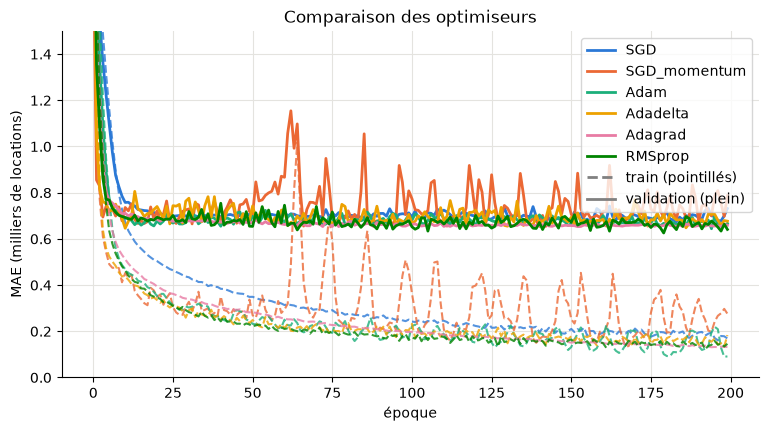

In [10]:
optimizers = {
    "SGD": lambda: keras.optimizers.SGD(learning_rate=0.01),
    "SGD_momentum": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "Adam": lambda: keras.optimizers.Adam(learning_rate=1e-3),
    "Adadelta": lambda: keras.optimizers.Adadelta(learning_rate=1.0),
    "Adagrad": lambda: keras.optimizers.Adagrad(learning_rate=0.01),
    "RMSprop": lambda: keras.optimizers.RMSprop(learning_rate=1e-3),
}
opts = {}
for name, make_opt in optimizers.items():
    lr = float(make_opt().learning_rate)
    _, opts[name] = run("02_optimiseurs", name, lambda: make_model(optimizer=make_opt()),
                        {"optimiseur": name, "lr": lr})

show("02_optimiseurs")
plot_history(opts, metric="mae", title="Comparaison des optimiseurs", ylim=(0, 1.5)); plt.show()

### 4.3 Architectures

Nombre de couches, nombre de neurones, puis fonction d'activation (sur 2 × 64).

03_architectures/relu_16                 MAE val =    608 vélos  (entraîné, 200 époques)
03_architectures/relu_64                 MAE val =    680 vélos  (entraîné, 200 époques)
03_architectures/relu_64x64              MAE val =    667 vélos  (entraîné, 200 époques)
03_architectures/relu_128x128            MAE val =    633 vélos  (entraîné, 200 époques)
03_architectures/relu_64x64x64           MAE val =    720 vélos  (entraîné, 200 époques)
03_architectures/relu_256x128x64         MAE val =    710 vélos  (entraîné, 200 époques)
03_architectures/tanh_64x64              MAE val =    661 vélos  (entraîné, 200 époques)
03_architectures/elu_64x64               MAE val =    615 vélos  (entraîné, 200 époques)
03_architectures/gelu_64x64              MAE val =    670 vélos  (entraîné, 200 époques)


,essai,données,batch_size,couches,activation,époques,MAE val (vélos),durée (s),params
0,relu_16,onehot,32,"(16,)",relu,200,608,39.5,628
7,elu_64x64,onehot,32,"(64, 64)",elu,200,615,67.9,6468
3,relu_128x128,onehot,32,"(128, 128)",relu,200,633,92.2,21060
6,tanh_64x64,onehot,32,"(64, 64)",tanh,200,661,69.4,6468
2,relu_64x64,onehot,32,"(64, 64)",relu,200,667,97.1,6468
8,gelu_64x64,onehot,32,"(64, 64)",gelu,200,670,38.8,6468
1,relu_64,onehot,32,"(64,)",relu,200,680,68.5,2308
5,relu_256x128x64,onehot,32,"(256, 128, 64)",relu,200,710,79.3,49988
4,relu_64x64x64,onehot,32,"(64, 64, 64)",relu,200,720,79.4,10628


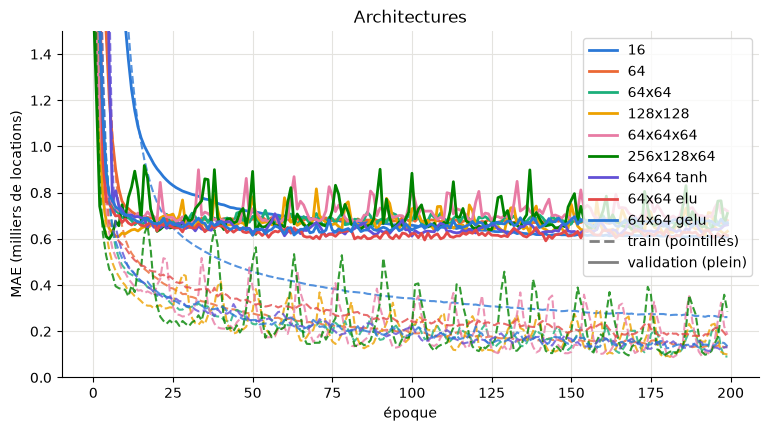

In [11]:
archis = {}
for hidden in [(16,), (64,), (64, 64), (128, 128), (64, 64, 64), (256, 128, 64)]:
    name = "x".join(map(str, hidden))
    _, archis[name] = run("03_architectures", f"relu_{name}", lambda: make_model(hidden=hidden),
                          {"couches": str(hidden), "activation": "relu"})
for act in ["tanh", "elu", "gelu"]:
    _, archis[f"64x64 {act}"] = run("03_architectures", f"{act}_64x64", lambda: make_model(activation=act),
                                    {"couches": "(64, 64)", "activation": act})

# nombre de paramètres de chaque modèle, lu sur les modèles sauvegardés
for r in results.values():
    if r["groupe"] == "03_architectures":
        r["params"] = keras.models.load_model(r["chemin"]).count_params()

show("03_architectures")
plot_history(archis, metric="mae", title="Architectures", ylim=(0, 1.5)); plt.show()

### 4.4 Learning rate schedules

- `ReduceLROnPlateau` : divise le learning rate quand la validation stagne ;
- `ExponentialDecay` : décroissance exponentielle à chaque pas ;
- `CosineDecay` : décroissance en cosinus jusqu'à ~0 en fin d'entraînement.

On part d'un learning rate élevé (1e-2) pour que l'effet soit visible.

04_lr_schedule/constant                  MAE val =    657 vélos  (entraîné, 200 époques)
04_lr_schedule/reduce_on_plateau         MAE val =    662 vélos  (entraîné, 200 époques)
04_lr_schedule/exponential_decay         MAE val =    665 vélos  (entraîné, 200 époques)
04_lr_schedule/cosine_decay              MAE val =    680 vélos  (entraîné, 200 époques)


,essai,données,batch_size,schedule,époques,MAE val (vélos),durée (s)
0,constant,onehot,32,constant,200,657,74.4
1,reduce_on_plateau,onehot,32,ReduceLROnPlateau,200,662,78.3
2,exponential_decay,onehot,32,ExponentialDecay,200,665,70.7
3,cosine_decay,onehot,32,CosineDecay,200,680,71.3


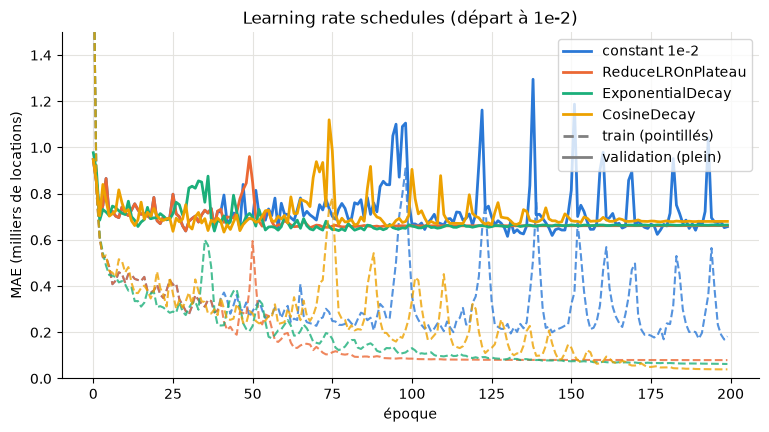

In [12]:
steps = int(np.ceil(len(DATASETS["onehot"]["train"][0]) / 32)) * EPOCHS
sched = {}
_, sched["constant 1e-2"] = run("04_lr_schedule", "constant",
                                lambda: make_model(optimizer=keras.optimizers.Adam(1e-2)), {"schedule": "constant"})
_, sched["ReduceLROnPlateau"] = run(
    "04_lr_schedule", "reduce_on_plateau", lambda: make_model(optimizer=keras.optimizers.Adam(1e-2)),
    {"schedule": "ReduceLROnPlateau"},
    callbacks=[keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=10, min_lr=1e-5)])
_, sched["ExponentialDecay"] = run(
    "04_lr_schedule", "exponential_decay",
    lambda: make_model(optimizer=keras.optimizers.Adam(
        keras.optimizers.schedules.ExponentialDecay(1e-2, decay_steps=steps // 10, decay_rate=0.6))),
    {"schedule": "ExponentialDecay"})
_, sched["CosineDecay"] = run(
    "04_lr_schedule", "cosine_decay",
    lambda: make_model(optimizer=keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(1e-2, steps))),
    {"schedule": "CosineDecay"})

show("04_lr_schedule")
plot_history(sched, metric="mae", title="Learning rate schedules (départ à 1e-2)", ylim=(0, 1.5)); plt.show()

## 5. Régularisation

Pour voir l'effet de la régularisation, il faut un modèle qui sur-apprend : on prend un réseau plus gros
(3 × 256) entraîné longtemps. Sur les courbes, l'écart entre train (pointillés) et validation (plein)
mesure le sur-apprentissage.

In [13]:
BIG = (256, 256, 256)

### 5.1 Dropout

05_dropout/dropout_0.0                   MAE val =    687 vélos  (entraîné, 200 époques)
05_dropout/dropout_0.1                   MAE val =    631 vélos  (entraîné, 200 époques)
05_dropout/dropout_0.2                   MAE val =    655 vélos  (entraîné, 200 époques)
05_dropout/dropout_0.3                   MAE val =    628 vélos  (entraîné, 200 époques)
05_dropout/dropout_0.5                   MAE val =    853 vélos  (entraîné, 200 époques)


,essai,données,batch_size,dropout,époques,MAE val (vélos),durée (s)
3,dropout_0.3,onehot,32,0.3,200,628,89.5
1,dropout_0.1,onehot,32,0.1,200,631,62.7
2,dropout_0.2,onehot,32,0.2,200,655,103.5
0,dropout_0.0,onehot,32,0.0,200,687,81.8
4,dropout_0.5,onehot,32,0.5,200,853,87.7


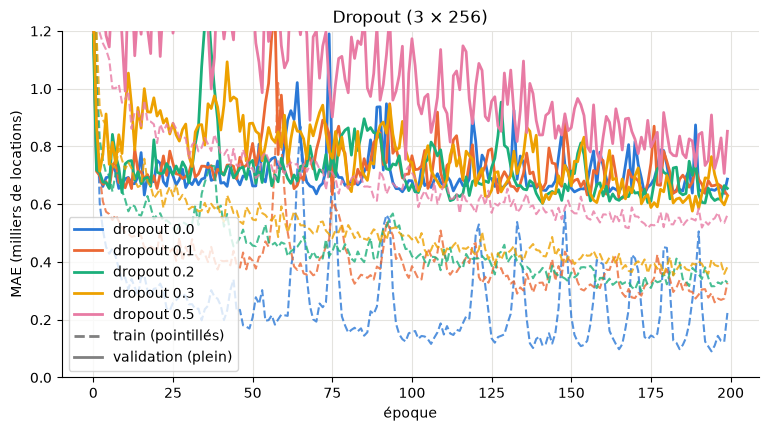

In [14]:
drops = {}
for rate in [0.0, 0.1, 0.2, 0.3, 0.5]:
    _, drops[f"dropout {rate}"] = run("05_dropout", f"dropout_{rate}",
                                      lambda: make_model(hidden=BIG, dropout=rate), {"dropout": rate})

show("05_dropout")
plot_history(drops, metric="mae", title="Dropout (3 × 256)", ylim=(0, 1.2)); plt.show()

### 5.2 Early stopping

On laisse jusqu'à 500 époques, mais l'entraînement s'arrête quand la MAE de validation ne s'améliore plus pendant
`patience` époques. `restore_best_weights=True` remet les poids de la meilleure époque.

06_early_stopping/sans                   MAE val =    659 vélos  (entraîné, 500 époques)
06_early_stopping/patience_10            MAE val =    632 vélos  (rechargé, 27 époques)
06_early_stopping/patience_30            MAE val =    632 vélos  (entraîné, 47 époques)


,essai,données,batch_size,early_stopping,patience,époques,MAE val (vélos),durée (s)
1,patience_10,onehot,32,True,10.0,27,632,0.0
2,patience_30,onehot,32,True,30.0,47,632,14.8
0,sans,onehot,32,False,NaN,500,659,161.1


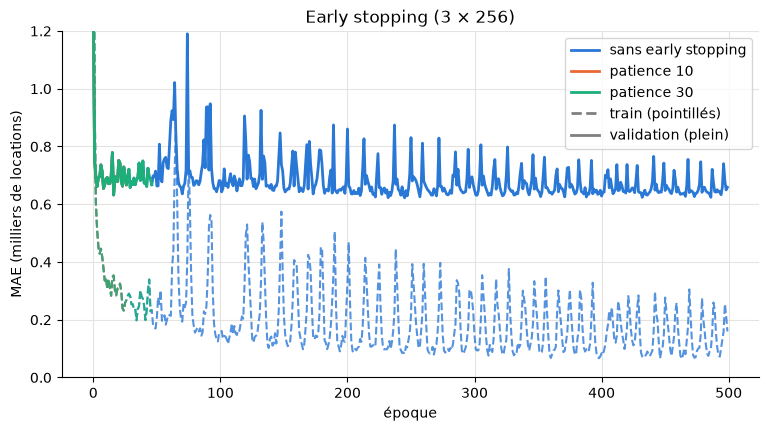

In [15]:
es = {}
_, es["sans early stopping"] = run("06_early_stopping", "sans", lambda: make_model(hidden=BIG),
                                   {"early_stopping": False, "patience": None}, epochs=500)
for patience in [10, 30]:
    _, es[f"patience {patience}"] = run(
        "06_early_stopping", f"patience_{patience}", lambda: make_model(hidden=BIG),
        {"early_stopping": True, "patience": patience}, epochs=500,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_mae", patience=patience, restore_best_weights=True)])

show("06_early_stopping")
plot_history(es, metric="mae", title="Early stopping (3 × 256)", ylim=(0, 1.2)); plt.show()

### 5.3 Taille de batch

Petit batch : beaucoup de mises à jour bruitées par époque (le bruit régularise un peu).
Grand batch : peu de mises à jour, plus stables, mais il faut plus d'époques. `full` = tout le train en un seul batch
(descente de gradient « classique »).

07_batch_size/batch_8                    MAE val =    707 vélos  (entraîné, 200 époques)
07_batch_size/batch_32                   MAE val =    667 vélos  (entraîné, 200 époques)
07_batch_size/batch_128                  MAE val =    650 vélos  (entraîné, 200 époques)
07_batch_size/batch_full                 MAE val =    649 vélos  (entraîné, 200 époques)


,essai,données,batch_size,époques,MAE val (vélos),durée (s)
3,batch_full,onehot,468,200,649,36.6
2,batch_128,onehot,128,200,650,48.0
1,batch_32,onehot,32,200,667,57.6
0,batch_8,onehot,8,200,707,87.1


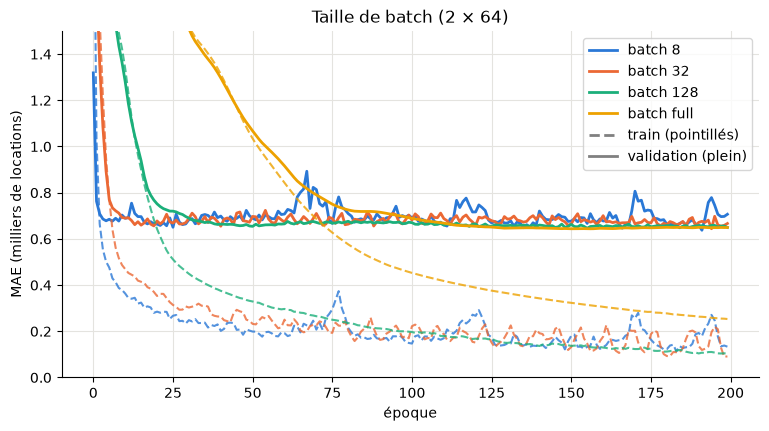

In [16]:
n_train = len(DATASETS["onehot"]["train"][0])
batches = {}
for bs in [8, 32, 128, n_train]:
    label = "full" if bs == n_train else str(bs)
    _, batches[f"batch {label}"] = run("07_batch_size", f"batch_{label}", lambda: make_model(),
                                       {}, batch_size=bs)

show("07_batch_size")
plot_history(batches, metric="mae", title="Taille de batch (2 × 64)", ylim=(0, 1.5)); plt.show()

### 5.4 Batch normalization

Normalise les activations de chaque couche sur le batch (placée entre `Dense` et l'activation).
Stabilise l'entraînement et autorise des learning rates plus grands.

08_batchnorm/bn_False_lr0.001            MAE val =    687 vélos  (entraîné, 200 époques)
08_batchnorm/bn_False_lr0.01             MAE val =    704 vélos  (entraîné, 200 époques)
08_batchnorm/bn_True_lr0.001             MAE val =    602 vélos  (entraîné, 200 époques)
08_batchnorm/bn_True_lr0.01              MAE val =    614 vélos  (entraîné, 200 époques)


,essai,données,batch_size,batchnorm,lr,époques,MAE val (vélos),durée (s)
2,bn_True_lr0.001,onehot,32,True,0.001,200,602,85.3
3,bn_True_lr0.01,onehot,32,True,0.010,200,614,78.1
0,bn_False_lr0.001,onehot,32,False,0.001,200,687,42.4
1,bn_False_lr0.01,onehot,32,False,0.010,200,704,53.0


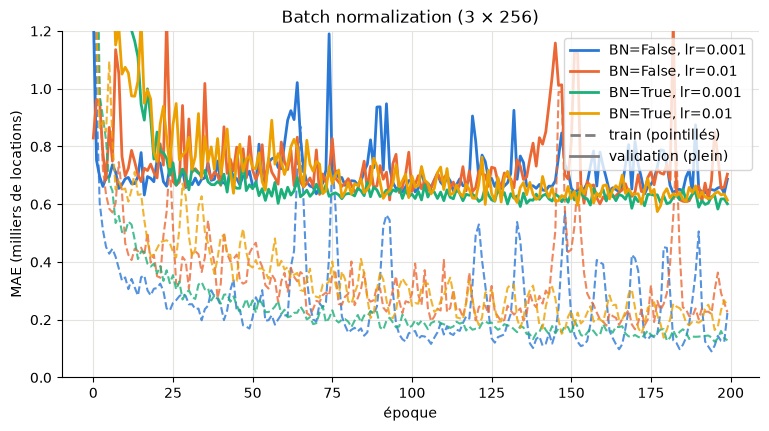

In [17]:
bns = {}
for bn in [False, True]:
    for lr in [1e-3, 1e-2]:
        _, bns[f"BN={bn}, lr={lr:g}"] = run(
            "08_batchnorm", f"bn_{bn}_lr{lr:g}",
            lambda: make_model(hidden=BIG, batchnorm=bn, optimizer=keras.optimizers.Adam(lr)),
            {"batchnorm": bn, "lr": lr})

show("08_batchnorm")
plot_history(bns, metric="mae", title="Batch normalization (3 × 256)", ylim=(0, 1.2)); plt.show()

### 5.5 Régularisation L1 / L2

Pénalité ajoutée à la loss : L2 pousse les poids vers de petites valeurs, L1 en met certains exactement à 0.
On compare la métrique `mae` (sans la pénalité) pour rester comparable.

09_l1_l2/l1_0_l2_0                       MAE val =    687 vélos  (entraîné, 200 époques)
09_l1_l2/l1_0_l2_0.001                   MAE val =    633 vélos  (entraîné, 200 époques)
09_l1_l2/l1_0_l2_0.01                    MAE val =    715 vélos  (entraîné, 200 époques)
09_l1_l2/l1_0.001_l2_0                   MAE val =    629 vélos  (entraîné, 200 époques)
09_l1_l2/l1_0.001_l2_0.001               MAE val =    622 vélos  (entraîné, 200 époques)


,essai,données,batch_size,l1,l2,époques,MAE val (vélos),durée (s)
4,l1_0.001_l2_0.001,onehot,32,0.001,0.001,200,622,77.8
3,l1_0.001_l2_0,onehot,32,0.001,0.000,200,629,71.8
1,l1_0_l2_0.001,onehot,32,0.000,0.001,200,633,84.4
0,l1_0_l2_0,onehot,32,0.000,0.000,200,687,80.2
2,l1_0_l2_0.01,onehot,32,0.000,0.010,200,715,79.7


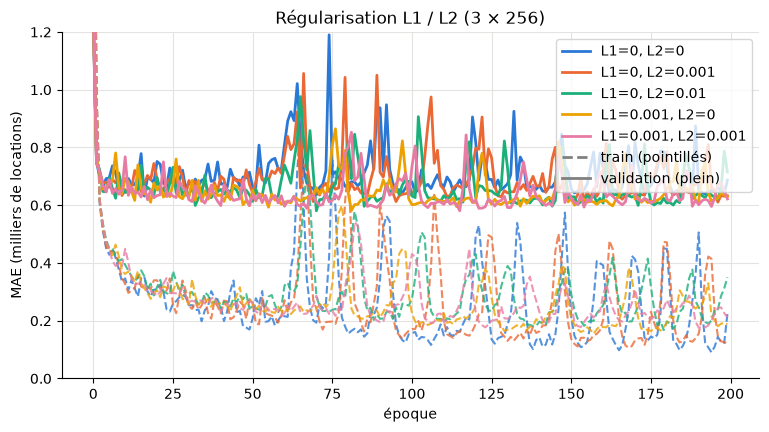

In [18]:
regs = {}
for l1, l2 in [(0, 0), (0, 1e-3), (0, 1e-2), (1e-3, 0), (1e-3, 1e-3)]:
    _, regs[f"L1={l1:g}, L2={l2:g}"] = run("09_l1_l2", f"l1_{l1:g}_l2_{l2:g}",
                                           lambda: make_model(hidden=BIG, l1=l1, l2=l2), {"l1": l1, "l2": l2})

show("09_l1_l2")
plot_history(regs, metric="mae", title="Régularisation L1 / L2 (3 × 256)", ylim=(0, 1.2)); plt.show()

### 5.6 Combiner les techniques

Dropout + batch norm + L2 + early stopping + ReduceLROnPlateau, comparé au même réseau sans régularisation.
Les valeurs sont à ajuster d'après les résultats des sections précédentes.

10_combine/dropout_bn_l2_es              MAE val =    551 vélos  (entraîné, 150 époques)


,essai,données,batch_size,dropout,batchnorm,l2,lr,époques,MAE val (vélos),durée (s)
0,dropout_bn_l2_es,onehot,32,0.2,True,0.0001,0.01,150,551,55.2


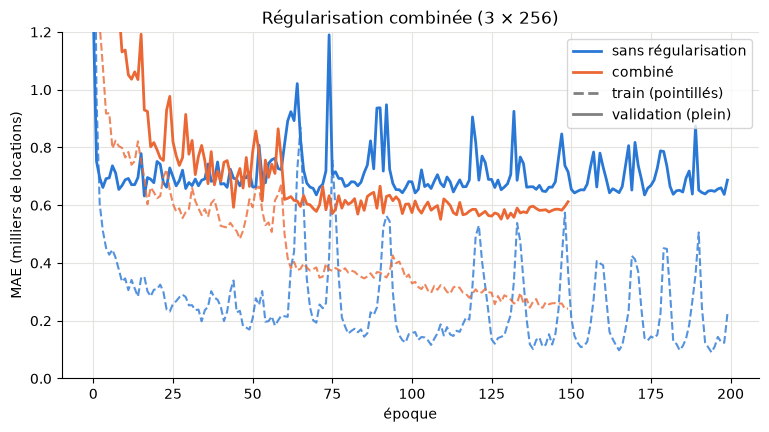

In [19]:
combo = {"sans régularisation": drops["dropout 0.0"]}
_, combo["combiné"] = run(
    "10_combine", "dropout_bn_l2_es",
    lambda: make_model(hidden=BIG, dropout=0.2, batchnorm=True, l2=1e-4, optimizer=keras.optimizers.Adam(1e-2)),
    {"dropout": 0.2, "batchnorm": True, "l2": 1e-4, "lr": 1e-2}, epochs=500,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_mae", patience=40, restore_best_weights=True),
               keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=15, min_lr=1e-5)])

show("10_combine")
plot_history(combo, metric="mae", title="Régularisation combinée (3 × 256)", ylim=(0, 1.2)); plt.show()

## 6. Évaluation

### 6.1 Tableau récapitulatif de tous les essais

Trié par MAE de validation. Il est aussi sauvegardé en CSV (`modeles/09_todo/recapitulatif.csv`).

,groupe,essai,données,MAE val (vélos),batch_size,couches,lr,époques,durée (s),encodage,optimiseur,activation,params,schedule,dropout,early_stopping,patience,batchnorm,l1,l2
0,10_combine,dropout_bn_l2_es,onehot,551,32.0,NaN,0.010,150.0,55.2,NaN,NaN,NaN,NaN,NaN,0.2,NaN,NaN,True,NaN,0.0001
1,00_encodage,cyclique,cyclique,565,32.0,NaN,NaN,200.0,0.0,cyclique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,08_batchnorm,bn_True_lr0.001,onehot,602,32.0,NaN,0.001,200.0,85.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,NaN
3,03_architectures,relu_16,onehot,608,32.0,"(16,)",NaN,200.0,39.5,NaN,NaN,relu,628.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,08_batchnorm,bn_True_lr0.01,onehot,614,32.0,NaN,0.010,200.0,78.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,NaN
5,03_architectures,elu_64x64,onehot,615,32.0,"(64, 64)",NaN,200.0,67.9,NaN,NaN,elu,6468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,09_l1_l2,l1_0.001_l2_0.001,onehot,622,32.0,NaN,NaN,200.0,77.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001,0.0010
7,05_dropout,dropout_0.3,onehot,628,32.0,NaN,NaN,200.0,89.5,NaN,NaN,NaN,NaN,NaN,0.3,NaN,NaN,NaN,NaN,NaN
8,09_l1_l2,l1_0.001_l2_0,onehot,629,32.0,NaN,NaN,200.0,71.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001,0.0000
9,05_dropout,dropout_0.1,onehot,631,32.0,NaN,NaN,200.0,62.7,NaN,NaN,NaN,NaN,NaN,0.1,NaN,NaN,NaN,NaN,NaN


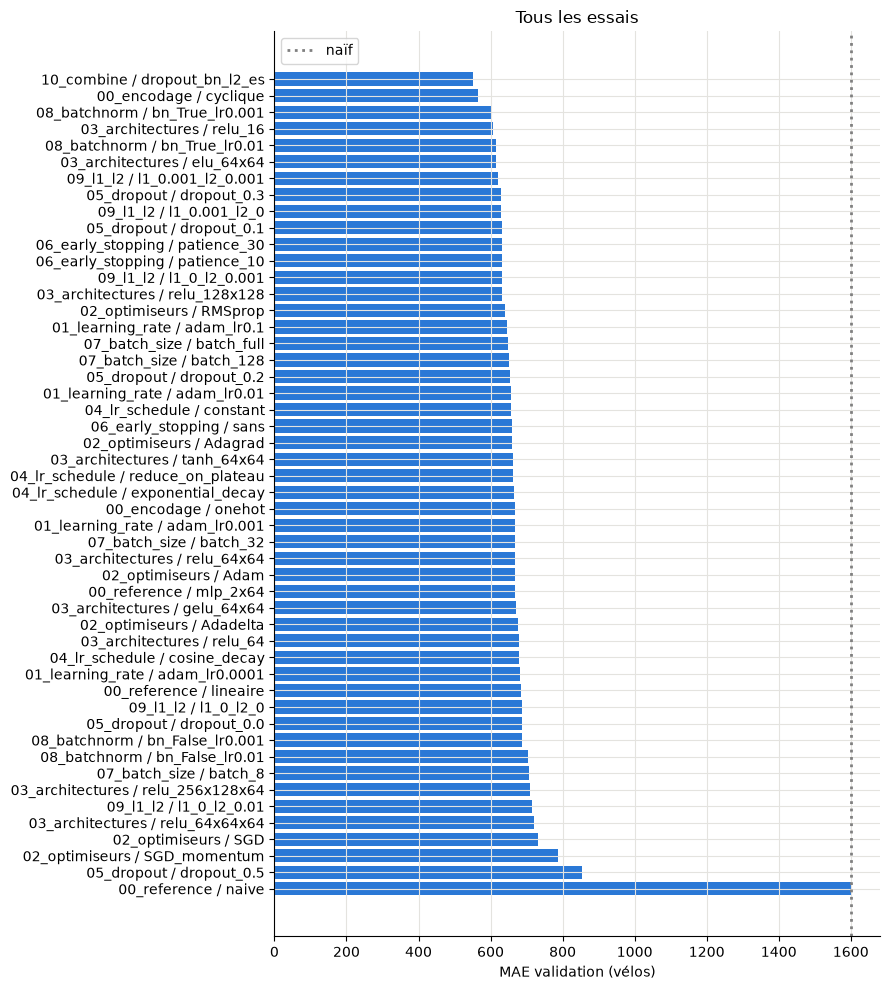

In [20]:
recap = (pd.DataFrame(results.values())
         .sort_values("MAE val (vélos)")
         .reset_index(drop=True))
MODEL_DIR.mkdir(parents=True, exist_ok=True)
recap.to_csv(MODEL_DIR / "recapitulatif.csv", index=False)
display(recap.drop(columns="chemin").head(15))

fig, ax = plt.subplots(figsize=(9, 10))
order = recap.iloc[::-1]
ax.barh(order["groupe"] + " / " + order["essai"], order["MAE val (vélos)"], color=PALETTE[0])
ax.axvline(naive_mae, color="gray", ls=":", label="naïf")
ax.set(xlabel="MAE validation (vélos)", title="Tous les essais")
ax.legend(); plt.tight_layout(); plt.show()

### 6.2 Test final du meilleur modèle

Le meilleur essai sur la validation est évalué **une seule fois** sur le jeu de test.
Si on modifie des essais après avoir regardé ce score, le test n'est plus un jeu « jamais vu ».

In [21]:
best = recap.dropna(subset=["chemin"]).iloc[0]
best_model = keras.models.load_model(best["chemin"])
Xte, yte = DATASETS[best["données"]]["test"]

pred = best_model.predict(Xte, verbose=0).ravel() * TARGET_SCALE
true = yte * TARGET_SCALE
test_mae = np.mean(np.abs(pred - true))
print(f"Meilleur essai : {best['groupe']}/{best['essai']}")
print(f"MAE validation : {best['MAE val (vélos)']:.0f} vélos")
print(f"MAE test       : {test_mae:.0f} vélos  (moyenne de cnt sur le test : {true.mean():.0f})")

Meilleur essai : 10_combine/dropout_bn_l2_es
MAE validation : 551 vélos
MAE test       : 479 vélos  (moyenne de cnt sur le test : 4451)


### 6.3 Prédictions vs réalité et résidus

Les résidus (réel − prédit) sont regroupés par saison et par météo pour voir où le modèle se trompe le plus.
Le graphique est aussi envoyé dans TensorBoard (onglet **Images**).

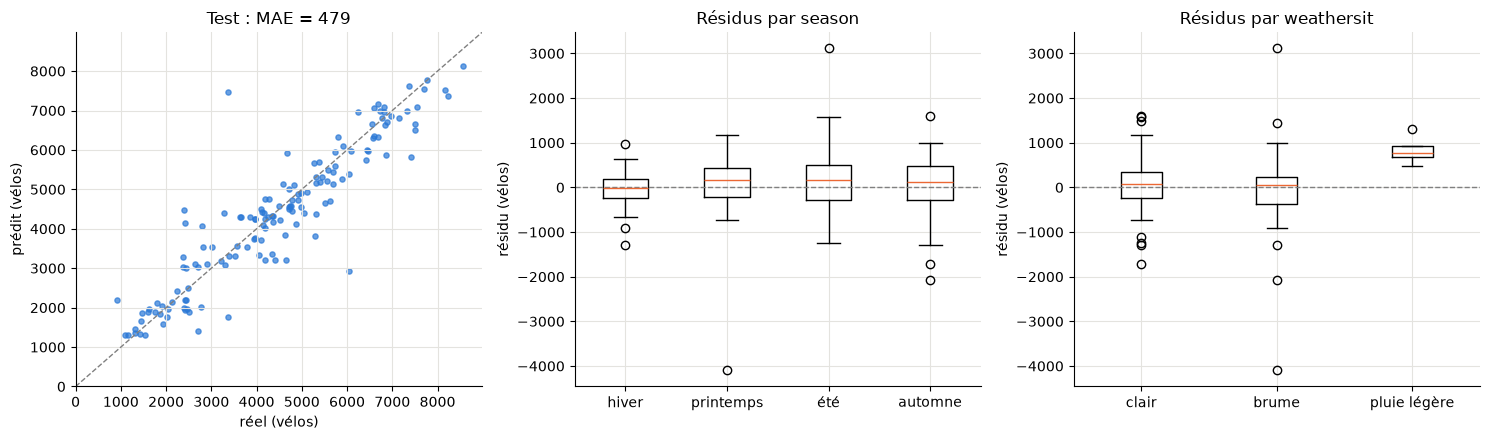

,biais moyen,MAE
season,,
automne,54.0,516.0
hiver,-56.0,301.0
printemps,52.0,509.0
été,213.0,575.0


In [22]:
test_raw = raw.loc[DATASETS[best["données"]]["test_index"]].copy()
test_raw["pred"] = pred
test_raw["residu"] = true - pred

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ax = axes[0]
ax.scatter(true, pred, s=14, alpha=0.7, color=PALETTE[0])
lim = [0, max(true.max(), pred.max()) * 1.05]
ax.plot(lim, lim, color="gray", ls="--", lw=1)
ax.set(xlim=lim, ylim=lim, xlabel="réel (vélos)", ylabel="prédit (vélos)", title=f"Test : MAE = {test_mae:.0f}")

seasons = {1: "hiver", 2: "printemps", 3: "été", 4: "automne"}
weather = {1: "clair", 2: "brume", 3: "pluie légère", 4: "forte pluie"}
for ax, col, labels in [(axes[1], "season", seasons), (axes[2], "weathersit", weather)]:
    groups = [(labels[k], g["residu"].to_numpy()) for k, g in test_raw.groupby(col)]
    ax.boxplot([g for _, g in groups], tick_labels=[n for n, _ in groups])
    ax.axhline(0, color="gray", ls="--", lw=1)
    ax.set(ylabel="résidu (vélos)", title=f"Résidus par {col}")
plt.tight_layout()

# Envoi de la figure dans TensorBoard
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=90)
image = tf.expand_dims(tf.image.decode_png(buf.getvalue(), channels=4), 0)
with tf.summary.create_file_writer(str(LOG_DIR / "evaluation")).as_default():
    tf.summary.image("test/predictions_et_residus", image, step=0)
    tf.summary.scalar("test/mae_velos", test_mae, step=0)
plt.show()

display(test_raw.groupby(test_raw["season"].map(seasons))["residu"].agg(["mean", lambda r: r.abs().mean()])
        .set_axis(["biais moyen", "MAE"], axis=1).round(0))

## 7. Sauvegarde

Tout ce qu'il faut pour réutiliser un modèle sans le réentraîner :

| Quoi | Où |
|---|---|
| Modèles (poids + architecture + optimiseur + **paramètres de normalisation**, inclus dans la couche `Normalization`) | `modeles/09_todo/<groupe>/<essai>.keras` |
| Historiques d'entraînement | `modeles/09_todo/<groupe>/<essai>.history.json` |
| Tableau récapitulatif | `modeles/09_todo/recapitulatif.csv` |
| Configuration du meilleur modèle (colonnes, échelle de la cible) | `modeles/09_todo/meilleur_modele.json` |
| Logs TensorBoard | `logs/09_todo/` |

`modeles/` et `logs/` sont dans le `.gitignore`.

In [23]:
config = {
    "modele": best["chemin"],
    "essai": f"{best['groupe']}/{best['essai']}",
    "donnees": best["données"],
    "colonnes": list((df_onehot if best["données"] == "onehot" else df_cyclic).drop(columns=TARGET).columns),
    "target_scale": TARGET_SCALE,
    "mae_val": float(best["MAE val (vélos)"]),
    "mae_test": float(test_mae),
}
(MODEL_DIR / "meilleur_modele.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))

# Rechargement : prédiction en nombre de vélos
reloaded = keras.models.load_model(config["modele"])
print(reloaded.predict(Xte[:5], verbose=0).ravel() * config["target_scale"])
print(true[:5])

[1367.8772 1312.1173 1591.2288 1344.011  1312.8901]
[1321. 1162. 1927. 1416. 1098.]


## À vous de jouer

- Dans TensorBoard, onglet **HParams** → *Parallel Coordinates View* : quels hyperparamètres comptent le plus ?
- Ajuster les valeurs de la section 5.6 d'après les meilleurs résultats des sections 5.1 à 5.5, puis relancer
  (seul l'essai modifié est réentraîné si on change son nom).
- Ajouter `hour.csv` et refaire les sections 3 et 4 : le réseau profite-t-il de 23× plus de données ?